<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/03%20-%20Unsupervised%20Learning/03b_clustering.ipynb)

# 03b — 聚类：让算法自动划分分子家族（Clustering）

在 `03a` 中，我们用 PCA 和 t-SNE 把高维化学空间投影到了二维平面上，肉眼能看到结构相似的分子聚成一个个“岛屿”。但在实际科研流程中，我们不能靠人眼在图上画圈来给几万个分子分组，更何况二维投影本身就会丢失或扭曲一部分高维距离信息。

**聚类（Clustering）**的任务，是在没有任何类别标签的情况下，直接根据样本之间的距离或密度，自动把数据集划分为若干个**簇（Cluster）**，使得同一簇内的分子彼此高度相似，不同簇的分子差异显著。

本节按照从底层原理到化学信息学实战的顺序展开：
1. **K-means 聚类**：在二维合成数据上手写迭代过程，直观理解“分配—更新质心”机制、局部最优陷阱与多次初始化（`n_init`）；
2. **如何选择簇数 $k$**：肘部法则（Elbow Method / Inertia）与轮廓系数（Silhouette Score）；
3. **K-means 的几何盲区与密度聚类（DBSCAN）**：如何识别非凸形状簇与离群噪声点；
4. **分子指纹空间的聚类**：高维化学空间的 Tanimoto 距离分布特征，以及化学信息学标准工具 **Taylor-Butina 聚类算法**；
5. **用聚类构建严格的模型外推测试集（Cluster Split / `GroupKFold`）**：定量检验模型在面对“全新结构家族”时的真实泛化能力。

In [1]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "03 - Unsupervised Learning"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


---

## 0. 环境准备

In [2]:
import os
os.environ["MKL_NUM_THREADS"] = "1"
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator
from rdkit.ML.Cluster import Butina
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, cross_val_score

RDLogger.DisableLog("rdApp.*")
plt.rcParams["figure.dpi"] = 110

<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [3]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


---

## 1. K-means 聚类：迭代机制与局部最优陷阱

### 1.1 从二维玩具数据看清楚算法在做什么

为了能直接用肉眼看清聚类的每一步几何操作，我们先用 `make_blobs` 生成一个包含 4 团高斯点云的二维合成数据集（假装不知道真实分组，画成全灰色）：

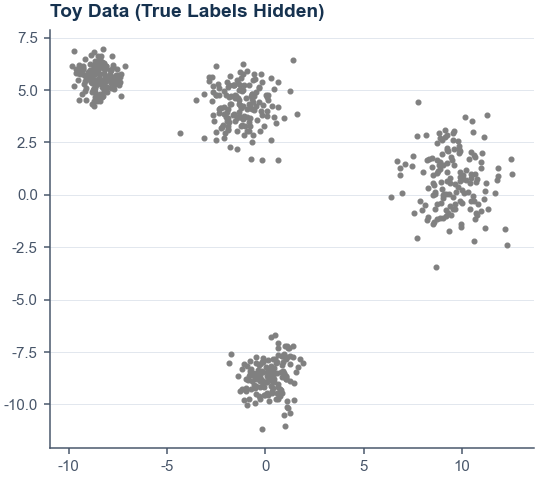

In [4]:
X_toy, y_toy = make_blobs(n_samples=600, centers=4, cluster_std=[0.6, 1.0, 1.4, 0.8], random_state=7)

plt.figure(figsize=(4.5, 4))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=8, color="gray")
plt.title("Toy Data (True Labels Hidden)")
plt.show()

### 1.2 手写 10 行代码拆解 K-means 的迭代步骤

**K-means** 是所有聚类算法中最基础、最快速的一种。给定预设的簇数 $k$，它的工作流程只有交替循环的两步：
1. **初始化（Initialization）**：在空间中随机挑选 $k$ 个点作为初始的**簇质心（Centroids）** $\mu_1, \dots, \mu_k$；
2. **分配步（Assignment）**：计算每个样本到 $k$ 个质心的欧氏距离，将每个样本归入离它最近的那个质心所在的簇；
3. **更新步（Update）**：重新计算每个簇内所有样本的坐标均值，把质心移动到新的均值位置；
4. **重复第 2–3 步**，直到质心位置不再发生变化（算法收敛）。

下面我们用纯 NumPy 手写这几步，并把前 4 轮迭代的质心位置（黑色 `X`）与簇划分画出来：

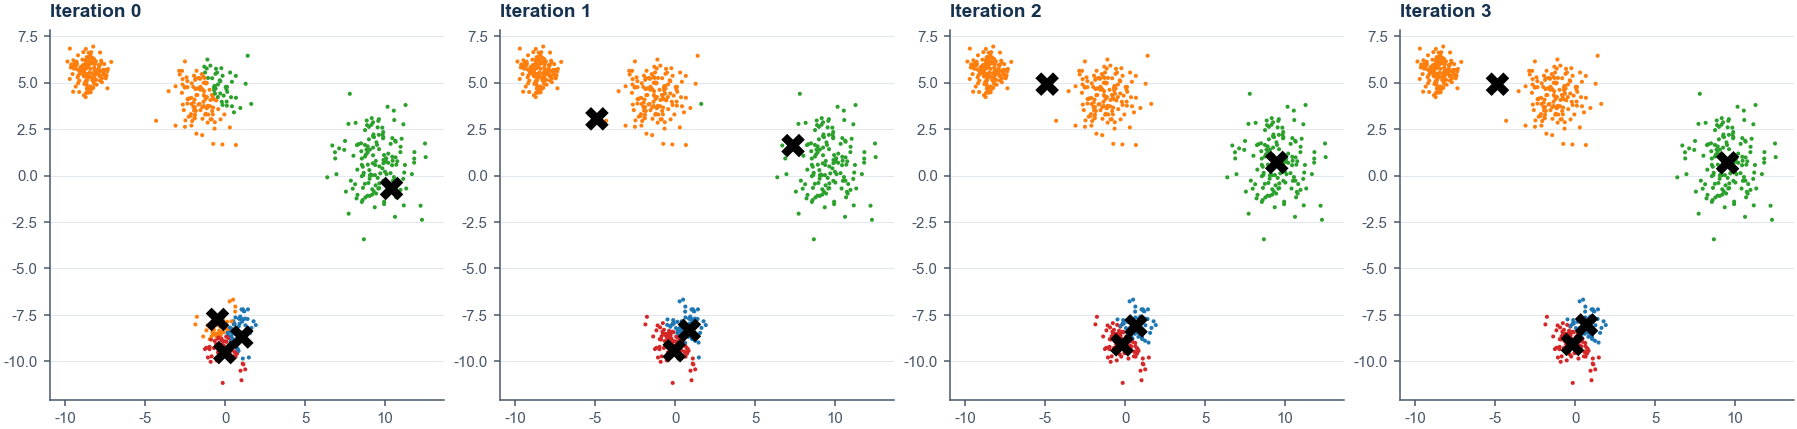

In [5]:
def kmeans_steps(X, k, n_steps, seed=3):
    rng = np.random.RandomState(seed)
    centroids = X[rng.choice(len(X), k, replace=False)]   # 1. 随机挑 k 个样本作为初始质心
    history = []
    for _ in range(n_steps):
        distances = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
        labels = distances.argmin(axis=1)                  # 2. 分配：归入最近的质心
        history.append((centroids.copy(), labels))
        centroids = np.array([X[labels == j].mean(axis=0) for j in range(k)])  # 3. 更新：移至簇均值
    return history

history = kmeans_steps(X_toy, k=4, n_steps=4, seed=3)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for step, (ax, (centroids, labels)) in enumerate(zip(axes, history)):
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=labels, s=6, cmap="tab10", vmin=0, vmax=9)
    ax.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200, c="black")
    ax.set_title(f"Iteration {step}")
plt.show()

### 1.3 局部最优陷阱与多次初始化（`n_init` & `k-means++`）

仔细看上面第 3 轮收敛后的图像，你会发现一个明显的错误：**左上角原本分开的两团点被合进了同一个蓝色簇，而正下方的一团点却被硬生生切成了两半！**

为什么会这样？看看 `Iteration 0`：由于随机抽样运气不好，4 个初始质心里有 3 个都落在了正下方那一团里。随后的每一步迭代都只是局部微调，无法跨过中间的空白区跳到左上角去。这说明 **K-means 只能保证收敛到局部最优（Local Optimum），不能保证全局最优**。

工程上的标准解决办法有两个（scikit-learn 的 `KMeans` 默认同时启用）：
1. **`k-means++` 智能初始化**：挑选初始质心时，让新质心尽量远离已经选出的质心，避免初始扎堆；
2. **多次随机重启（`n_init=10`）**：换 10 组不同的随机初始质心独立跑完 K-means，最后自动保留簇内总平方距离（称为**惯性 Inertia**）最小的那一次结果。

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


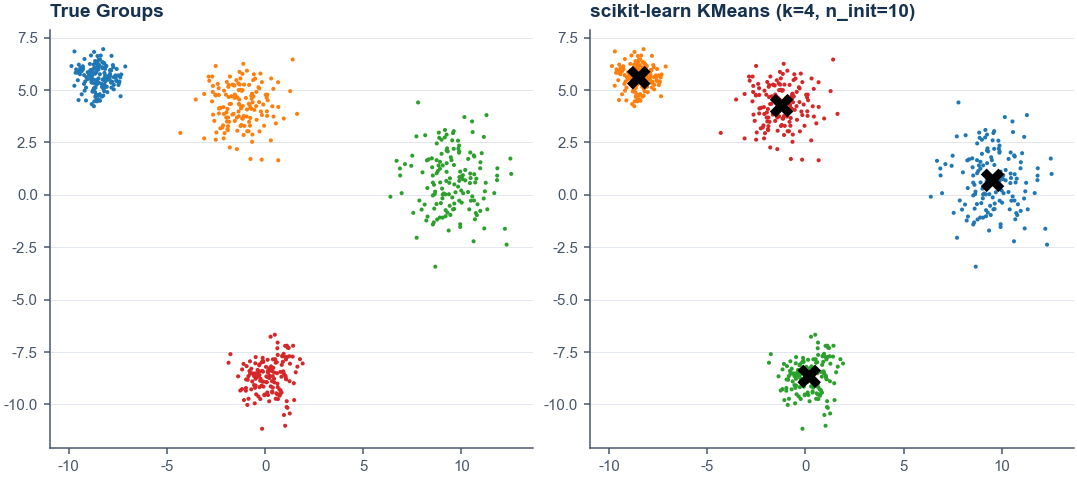

In [6]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_toy)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, s=6, cmap="tab10", vmin=0, vmax=9)
axes[0].set_title("True Groups")

axes[1].scatter(X_toy[:, 0], X_toy[:, 1], c=kmeans.labels_, s=6, cmap="tab10", vmin=0, vmax=9)
axes[1].scatter(*kmeans.cluster_centers_.T, marker="X", s=200, c="black")
axes[1].set_title("scikit-learn KMeans (k=4, n_init=10)")
plt.show()

> **关于簇编号颜色的小细节**：无监督聚类给每个簇分配的整数编号（`0, 1, 2, 3`）是任意的，因此左图和右图的颜色标签不必一一对应，只要相同的样本点被分在同一个簇内即可。

---

## 2. 如何确定簇数 $k$？肘部法则与轮廓系数

K-means 要求事先指定簇数 $k$。但在面对未知的化学数据集时，我们事先并不知道里面有几个分子家族。常用的定量参考指标有两个：

1. **簇内平方和 / 惯性（Inertia）与肘部法则（Elbow Method）**：
   $$\text{Inertia} = \sum_{i=1}^{N} \|x_i - \mu_{c(i)}\|^2$$
   随着簇数 $k$ 增加，每个簇变小，Inertia 必然单调下降（极端情况 $k=N$ 时 Inertia 为 0）。因此我们不能选 Inertia 最小的 $k$，而是寻找曲线由陡变缓的**拐点（“手肘”位置，Elbow）**：拐点之后再增加 $k$ 带来的紧致度收益已非常有限。

2. **轮廓系数（Silhouette Score，越大越好）**：
   对每个样本 $i$，计算它到**同簇其他样本**的平均距离 $a_i$（衡量簇内紧致度）以及它到**最近的另一个簇所有样本**的平均距离 $b_i$（衡量簇间分离度），定义：
   $$s_i = \frac{b_i - a_i}{\max(a_i, b_i)} \in [-1, 1]$$
   全体样本的平均 $s_i$ 即为轮廓系数：越接近 `1` 说明“簇内抱团紧、簇间离得远”；接近 `0` 说明样本处于两簇交界处；为负说明样本可能被分错了簇。

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarn

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


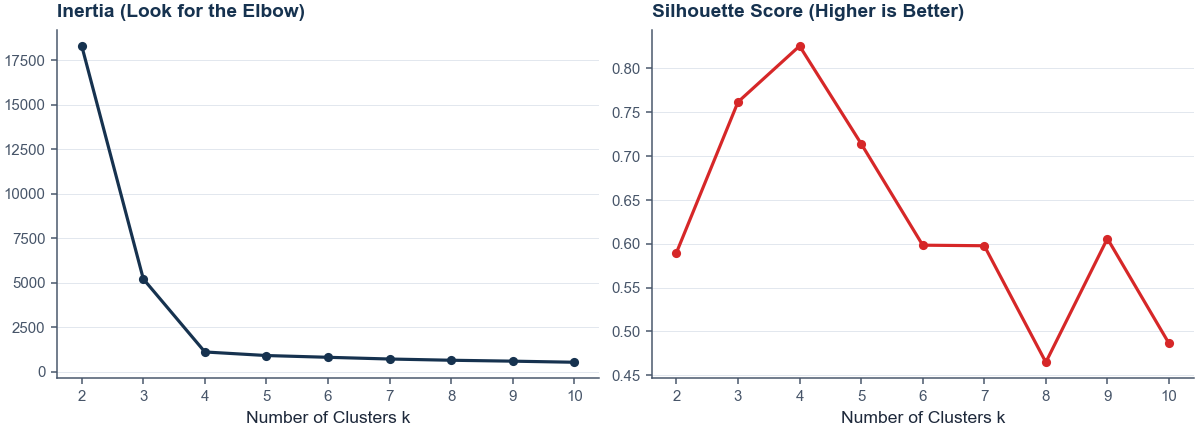

轮廓系数最大的最优簇数 k = 4


In [7]:
ks = range(2, 11)
inertias, silhouettes = [], []
for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_toy)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_toy, model.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(ks, inertias, "o-")
axes[0].set_xlabel("Number of Clusters k")
axes[0].set_title("Inertia (Look for the Elbow)")

axes[1].plot(ks, silhouettes, "o-", color="tab:red")
axes[1].set_xlabel("Number of Clusters k")
axes[1].set_title("Silhouette Score (Higher is Better)")
plt.show()

print("轮廓系数最大的最优簇数 k =", ks[int(np.argmax(silhouettes))])

在理想合成数据上，Inertia 在 $k=4$ 处出现清晰的肘部拐点，轮廓系数也在 $k=4$ 处达到峰值。

> **真实科研数据的提醒**：在真实的分子库（如 `03c` 即将看到的膦配体库）中，分子在化学空间里往往呈连续过渡分布，Inertia 曲线常常平滑下降而没有明显拐点，轮廓系数也普遍在 `0.15 ~ 0.30` 之间。此时，$k$ 的选择不能机械迷信单一统计指标，而要结合**领域先验知识**与下游实验筛选的目标规模。

---

## 3. K-means 的凸形假设盲区与基于密度的聚类（DBSCAN）

K-means 将每个样本简单归入距离最近的单个质心，这意味着它在几何上相当于用垂直平分超平面切割空间，切出来的簇永远是**球状/凸多面体（Convex Clusters）**。

如果数据在高维流形或降维平面上呈弯曲条带状（例如下面交错的两个半月形 `make_moons`），或者数据里混有许多零散的异常离群点，K-means 就会硬生生从中间一刀切错。

此时需要使用**基于密度的聚类算法 DBSCAN**（Density-Based Spatial Clustering of Applications with Noise）：
- 如果一个点在半径 `eps` 邻域内至少包含 `min_samples` 个点，则称其为**核心点（Core Point）**；
- 彼此距离在 `eps` 以内的核心点及其邻域点连通形成一个簇（可以沿着任意弯曲形状生长）；
- 既不是核心点、也不在任何核心点邻域内的孤立点，会被自动标记为 **`-1`（噪声/离群点，Noise）**，而不会被强行塞进某个簇里。

c:\Users\18101\anaconda3\envs\zesheng\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


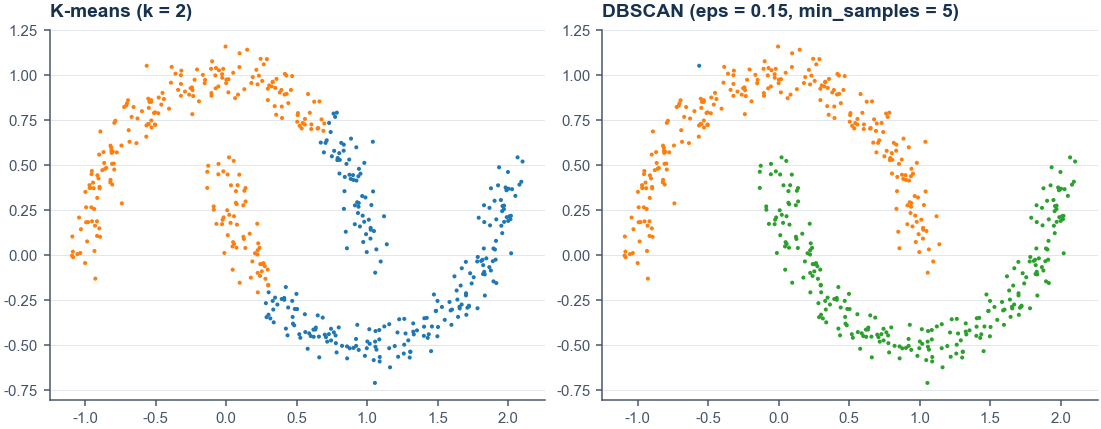

DBSCAN 识别出的簇标签: [-1, 0, 1] （其中 -1 代表孤立噪声点）


In [8]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.07, random_state=0)
km_moons = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_moons)
db_moons = DBSCAN(eps=0.15, min_samples=5).fit(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))
axes[0].scatter(*X_moons.T, c=km_moons.labels_, s=6, cmap="tab10", vmin=0, vmax=9)
axes[0].set_title("K-means (k = 2)")

axes[1].scatter(*X_moons.T, c=db_moons.labels_, s=6, cmap="tab10", vmin=-1, vmax=9)
axes[1].set_title("DBSCAN (eps = 0.15, min_samples = 5)")
plt.show()

print("DBSCAN 识别出的簇标签:", sorted(set(db_moons.labels_)), "（其中 -1 代表孤立噪声点）")

| 特性对比 | K-means | DBSCAN |
|---|---|---|
| **是否需要预设簇数 $k$** | 必须指定 `n_clusters=k` | 不需要（自动根据密度连通性发现簇数） |
| **适用的簇几何形状** | 仅限球状 / 凸形团块 | 任意弯曲、环状或条带状流形 |
| **对离群点（Outliers）的处理** | 强行并入最近的簇（且会拉偏质心） | 自动识别并单独标记为 `-1`（噪声点） |
| **核心敏感超参数** | 簇数 $k$ | 邻域半径 `eps` 与最小样本数 `min_samples` |

### 🏋️ 练习 03b-1：探究邻域半径 `eps` 对 DBSCAN 的决定性影响

保持 `min_samples=5` 不变，把上面半月形数据的 DBSCAN 参数 `eps` 分别改为 `0.05`（过小）和 `0.5`（过大）：
1. 每次打印识别出的有效簇数（不含 `-1`）和噪声点个数（`labels == -1`）；
2. 将 `eps = 0.05, 0.15, 0.5` 的三张聚类散点图并排画出来，解释为什么 `eps` 过小或过大都会导致聚类失效。

In [9]:
# 在下方填写你的代码：


---

## 4. 分子指纹空间的聚类：Tanimoto 距离与 Taylor-Butina 算法

### 4.1 高维化学空间的距离分布：为什么绝大多数分子彼此“不像”？

将聚类用于真实分子库时，最核心的问题是如何度量两个分子之间的“距离”。对于 2048 位 Morgan 指纹，化学信息学统一使用基于 **Tanimoto 相似度**（即 Jaccard 相似度）定义的 **Tanimoto 距离**：
$$d_{\text{Tanimoto}}(A, B) = 1 - S_{\text{Tanimoto}}(A, B) = 1 - \frac{|A \cap B|}{|A \cup B|} \in [0, 1]$$

AqSolDB 共有 9,480 个分子，两两距离共有 $\frac{9480 \times 9479}{2} \approx 4500$ 万对。为了快速演示，我们先随机抽取 2,000 个分子（约 200 万对距离），用 RDKit 的 `BulkTanimotoSimilarity` 算出完整的下三角距离数组，并画出距离分布直方图：

两两距离总数: 1999000 (= 2000 × 1999 / 2)


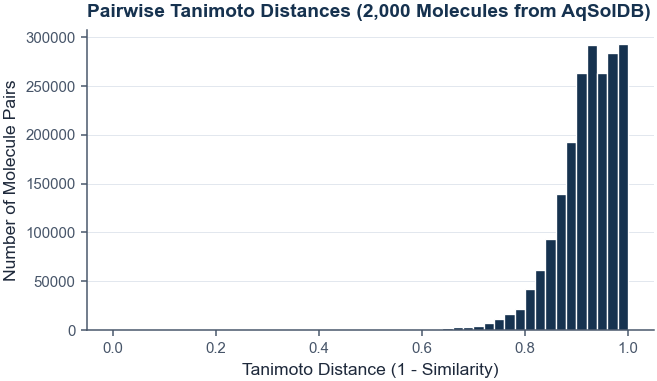

Tanimoto 距离 < 0.4（即相似度 > 0.6）的分子对仅占: 0.03%


In [10]:
DATA_FILE = "data/solubility.csv"
if not os.path.exists(DATA_FILE):
    DATA_FILE = "solubility.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("请上传 solubility.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("找不到 solubility.csv，请确保它位于当前目录或 data/ 文件夹下")

df = pd.read_csv(DATA_FILE)
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)

fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
sub = df.iloc[np.random.RandomState(0).choice(len(df), 2000, replace=False)].reset_index(drop=True)
sub_fps = [fp_gen.GetFingerprint(m) for m in sub["mol"]]

# 计算下三角距离向量：依次存放第 i 个分子与前 i 个分子的 Tanimoto 距离（Butina 算法要求的输入格式）
distances = []
for i in range(1, len(sub_fps)):
    sims = DataStructs.BulkTanimotoSimilarity(sub_fps[i], sub_fps[:i])
    distances.extend(1.0 - np.array(sims))
distances = np.array(distances)
print(f"两两距离总数: {len(distances)} (= 2000 × 1999 / 2)")

plt.figure(figsize=(5.5, 3.2))
plt.hist(distances, bins=50)
plt.xlabel("Tanimoto Distance (1 - Similarity)")
plt.ylabel("Number of Molecule Pairs")
plt.title("Pairwise Tanimoto Distances (2,000 Molecules from AqSolDB)")
plt.show()

print(f"Tanimoto 距离 < 0.4（即相似度 > 0.6）的分子对仅占: {np.mean(distances < 0.4):.2%}")

### 4.2 凝聚层次聚类（Hierarchical Clustering）与分子家族树状图

除了预设簇数 $k$ 的划分法外，经典机器学习中另一大支柱是**自底向上的凝聚层次聚类（Agglomerative Clustering）**：
1. 起初把每个分子都看作独立的一小簇；
2. 每一步找出距离最近的两个簇合并成新簇（常用 **Ward 方差最小化准则** 或 **平均连接 Average Linkage**），如此层层向上合并直到所有分子汇成一棵大树；
3. 画出的**树状图（Dendrogram）**不仅完全不需要预先猜 $k$，还能直观展现分子间的亲缘层级——在任意高度横切一刀，就能按需得到粗粒度大类或细粒度亚族！

下面我们挑选 14 个代表性有机半导体母核、杂环与极性有机小分子，在标准化 17 维描述符空间绘制它们的化学亲缘树状图：

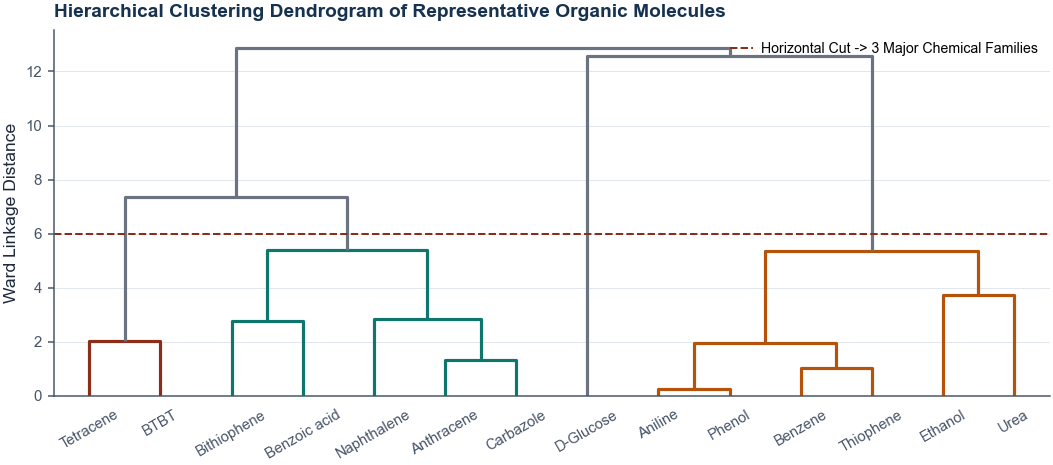

In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from rdkit.Chem import Descriptors

rep_mols = [
    ("Benzene", "c1ccccc1"), ("Naphthalene", "c1ccc2ccccc2c1"),
    ("Anthracene", "c1ccc2cc3ccccc3cc2c1"), ("Tetracene", "c1ccc2cc3cc4ccccc4cc3cc2c1"),
    ("Thiophene", "c1ccsc1"), ("Bithiophene", "c1cc(-c2cccs2)sc1"),
    ("BTBT", "c1ccc2c(c1)sc1c2sc2ccccc21"), ("Carbazole", "c1ccc2c(c1)[nH]c1ccccc12"),
    ("Aniline", "Nc1ccccc1"), ("Phenol", "Oc1ccccc1"),
    ("Benzoic acid", "O=C(O)c1ccccc1"), ("Ethanol", "CCO"),
    ("Urea", "NC(N)=O"), ("D-Glucose", "OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O"),
]
fcols_17 = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA", "BalabanJ", "BertzCT",
]
X_rep = np.array([[getattr(Descriptors, k)(Chem.MolFromSmiles(s)) for k in fcols_17] for _, s in rep_mols])
X_rep_s = StandardScaler().fit_transform(X_rep)

Z_link = linkage(X_rep_s, method="ward")
fig, ax = plt.subplots(figsize=(8.8, 3.9))
dendrogram(Z_link, labels=[n for n, _ in rep_mols], leaf_rotation=30, leaf_font_size=8.8,
           color_threshold=6.0, above_threshold_color=C.slate, ax=ax)
ax.axhline(6.0, color=C.crimson, ls="--", lw=1.2, label="Horizontal Cut -> 3 Major Chemical Families")
ax.set_ylabel("Ward Linkage Distance")
ax.set_title("Hierarchical Clustering Dendrogram of Representative Organic Molecules")
ax.legend(fontsize=8.5, loc="upper right")
plt.show()

直方图清晰展示了高维分子指纹空间的普遍统计特征：**绝大部分分子对之间的 Tanimoto 距离都在 `0.85` 以上（相似度低于 `0.15`），距离小于 `0.4` 的高相似近亲只占万分之三（`0.03%`）！**

### 4.3 化学信息学标准工具：Taylor-Butina 球形排除聚类

在如此稀疏的指纹空间里，如果强行用 K-means 把 2,000 个分子分成 10 个簇，大量毫无关系的分子会被硬塞进同一个簇，且算出的质心是无法对应任何真实分子的浮点数向量。

因此，药物化学与材料信息学中最常使用 **Taylor-Butina 聚类算法**（RDKit 内置为 `Butina.ClusterData`）：
1. 设定一个最大距离阈值 `cutoff`（例如 `0.6`，对应 Tanimoto 相似度 $\ge 0.4$），统计每个分子在距离 `cutoff` 以内有多少个邻居；
2. 挑出**邻居数最多**的那个真实分子作为第 1 个簇的**中心代表分子（Centroid Molecule）**，将它及其阈值内的所有邻居打包成第 1 个簇，并从待分配列表中移除；
3. 在剩余分子中重复第 2 步，直到所有分子分配完毕。

**Butina 聚类的三大优势**：不需要预设簇数 $k$；保证簇内每个成员到中心分子的距离严格不超过 `cutoff`；每个簇的中心都是一个**真实存在的代表性分子**（非常适合从十万级化合物库中每个簇只挑中心分子进行高通量实验采购）。

In [12]:
cutoff = 0.6   # Tanimoto 距离阈值（即要求簇成员与中心分子的相似度 >= 0.4）
clusters = Butina.ClusterData(distances, len(sub_fps), cutoff, isDistData=True)
sizes = sorted((len(c) for c in clusters), reverse=True)

print(f"cutoff = {cutoff}: 共生成 {len(clusters)} 个簇，其中包含 {sum(s == 1 for s in sizes)} 个单分子孤立簇（Singletons）")
print("前 5 大簇的成员数量:", sizes[:5])

cutoff = 0.6: 共生成 1023 个簇，其中包含 698 个单分子孤立簇（Singletons）
前 5 大簇的成员数量: [58, 32, 30, 29, 20]


2,000 个分子分出了 1,023 个簇，其中 698 个簇里只有 1 个分子（单分子簇 Singleton）。这不是算法出了问题，而是忠实反映了 AqSolDB 极高的结构多样性：那 698 个分子在子集中确实没有相似度超过 `0.4` 的近亲，Butina 拒绝把不相干的分子硬凑成一团。

下面我们把规模最大的前 3 个簇画出来（每个簇的第 1 个分子 `members[0]` 就是该簇的真实中心分子）：

第 1 大簇（共 58 个分子）：


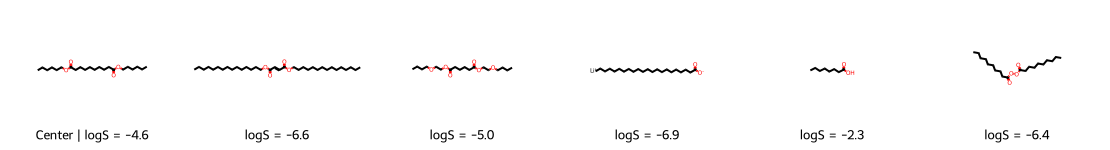

第 2 大簇（共 32 个分子）：


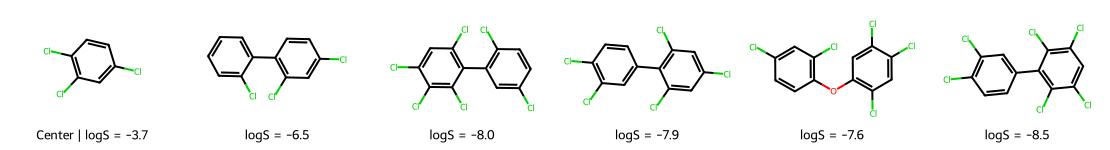

第 3 大簇（共 30 个分子）：


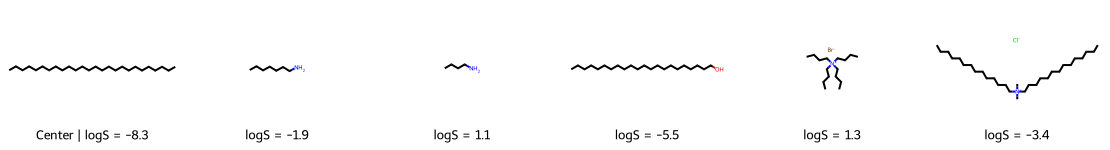

In [13]:
largest = sorted(clusters, key=len, reverse=True)[:3]
for rank, members in enumerate(largest, start=1):
    shown = list(members[:6])   # members[0] 即为簇中心代表分子
    legends = [
        ("Center | " if j == 0 else "") + f"logS = {sub['Solubility'][i]:.1f}"
        for j, i in enumerate(shown)
    ]
    img = Draw.MolsToGridImage(
        [sub["mol"][i] for i in shown],
        molsPerRow=6,
        subImgSize=(185, 150),
        legends=legends,
    )
    print(f"第 {rank} 大簇（共 {len(members)} 个分子）：")
    display(img)

前三大簇分别对应数据集中高频出现的三个典型同系物家族：
1. **第 1 大簇**：长链脂肪酸及其羧酸酯；
2. **第 2 大簇**：氯代苯与多氯联苯（PCBs，经典持久性环境污染物）；
3. **第 3 大簇**：直链烷基胺、脂肪醇、季铵盐与直链烷烃。

注意观察第 3 大簇中各个分子的 `logS`：从 `+1.3`（极易溶的短链/极性头基分子）一直跨到 `-8.3`（极难溶的超长链烷烃），整整跨越了近 10 个数量级！这再次呼应了 `03a` 的结论：**二值 Morgan 指纹只记录“有哪些局部碎片”，长碳链的重复 `-CH2-` 碎片让它们在 Tanimoto 距离下聚为一簇，但链长与端基电荷却彻底改变了水溶性。**

### 🏋️ 练习 03b-2：盲测未知分子库的家族数量与化学身份

`data/unknown_clusters.csv` 中存放了 900 个未标明类别的分子 SMILES。请你用无监督聚类揭开它们的真实身份：
1. 读取 `data/unknown_clusters.csv`，计算 2048 位 Morgan 指纹并转为布尔型 NumPy 数组 `X_unknown`（`dtype=bool`）；
2. 对 $k = 2, \dots, 8$ 依次运行 `KMeans(n_clusters=k, n_init=10, random_state=42)`，画出 Inertia 曲线和基于 Jaccard（即 Tanimoto）距离的轮廓系数曲线 `silhouette_score(X_unknown, labels, metric="jaccard")`；
3. 根据曲线选出最合理的簇数 `best_k`，从每个簇中随机抽取 5 个分子用 `Draw.MolsToGridImage` 画出来，用肉眼辨认这几个簇分别属于什么化学大类（提示：观察重复单元是氨基酸肽键、糖环还是合成寡聚酯/烯烃片段？）；
4. 读取真实标签 `data/unknown_clusters_labels.csv` 的 `label` 列，用**调整兰德指数（Adjusted Rand Index, `adjusted_rand_score(truth, labels)`）**定量评估你的无监督聚类与真实分类的一致性（`ARI = 1.0` 代表 100% 完美吻合，`0.0` 代表随机胡猜）。

In [14]:
# 在下方填写你的代码：


---

## 5. 实战应用：用聚类划分（Cluster Split）严格检验模型外推能力

在第二讲 `02e` 中我们学过交叉验证与适用域：如果使用普通的随机划分（Random Split / `KFold`），像上面看到的多氯联苯、长链脂肪酸等包含几十个同系物的家族，会被随机打散到训练集和测试集中。这样一来，测试集里的分子在训练集里总能找到结构极其相似的“同胞兄弟”，测出来的 RMSE 反映的其实是**同系物内部插值（Interpolation）**的精度，往往过于乐观。

如果我们的目标是评估模型**面对从未见过的全新分子家族时的外推能力（Extrapolation）**，就可以利用聚类来进行**按簇分组交叉验证（Cluster Split / `GroupKFold`）**：
1. 先用 `PCA(50)` + `KMeans(n_clusters=50)` 将全部 9,480 个分子按指纹划分为 50 个结构簇；
2. 将簇编号 `groups` 传给 `GroupKFold(n_splits=5)`：**保证同一个簇的所有分子要么全部进训练集，要么全部进测试集**，绝不跨集拆分；
3. 对比随机 5 折（Random 5-Fold）与按簇 5 折（Cluster 5-Fold）下随机森林回归器的测试 RMSE：

In [15]:
feature_cols = [
    "MolWt", "MolLogP", "MolMR", "HeavyAtomCount", "NumHAcceptors", "NumHDonors",
    "NumHeteroatoms", "NumRotatableBonds", "NumValenceElectrons", "NumAromaticRings",
    "NumSaturatedRings", "NumAliphaticRings", "RingCount", "TPSA", "LabuteASA",
    "BalabanJ", "BertzCT",
]
X = df[feature_cols].values
y = df["Solubility"].values

fps = np.array([fp_gen.GetFingerprintAsNumPy(m) for m in df["mol"]], dtype=np.uint8)
fp_50 = PCA(n_components=50, random_state=0).fit_transform(fps)
groups = KMeans(n_clusters=50, n_init=10, random_state=42).fit_predict(fp_50)
print(f"50 个指纹簇的规模范围: 最小簇 {np.bincount(groups).min()} 个分子 | 最大簇 {np.bincount(groups).max()} 个分子\n")

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
splits = {
    "Random 5-Fold":  KFold(n_splits=5, shuffle=True, random_state=42).split(X),
    "Cluster 5-Fold": GroupKFold(n_splits=5).split(X, y, groups),
}
cv_results = {}
for name, split in splits.items():
    scores = -cross_val_score(rf, X, y, cv=list(split), scoring="neg_root_mean_squared_error")
    cv_results[name] = scores
    print(f"{name:15s}: 各折 RMSE {np.round(scores, 2)} -> 平均 {scores.mean():.2f} ± {scores.std():.2f}")

50 个指纹簇的规模范围: 最小簇 15 个分子 | 最大簇 578 个分子



Random 5-Fold  : 各折 RMSE [1.18 1.14 1.12 1.1  1.17] -> 平均 1.14 ± 0.03


Cluster 5-Fold : 各折 RMSE [1.55 1.21 1.14 1.13 1.33] -> 平均 1.27 ± 0.16


对比结果非常直观：
- 在 **Random 5-Fold** 下，5 折的平均 RMSE 为 **`1.14 ± 0.03`**，各折之间极其平稳；
- 切换到 **Cluster 5-Fold** 后，一旦禁止测试集分子在训练集里拥有同簇近亲，平均 RMSE 立刻恶化到 **`1.27 ± 0.15`**（最难的一折甚至高达 `1.51`）！

这就是为什么现在高水平的 AI for Materials / AI for Chemistry 论文在汇报模型性能时，除了报告随机划分（Random Split），往往必须同时报告 **Cluster Split** 或 **Scaffold Split（骨架划分）**：两者的差距越大，说明模型越依赖对局部相似结构的“死记硬背”，向全新化学空间外推时的衰减就越明显。

### 🏋️ 练习 03b-3：聚类粒度（簇数 `n_clusters`）如何影响 Cluster Split 的难度？

把上面 `KMeans` 的簇数分别改为 `n_clusters = 10`（粗粒度大簇）和 `n_clusters = 500`（细粒度小簇），重新运行 `GroupKFold(n_splits=5)` 交叉验证并对比平均 RMSE。
- 思考：为什么簇数越多（例如分成 500 个小簇甚至每个分子单独一簇），Cluster Split 的 RMSE 就越接近随机划分？

In [16]:
# 在下方填写你的代码：


---

## 小结

| 方法与概念 | 核心要点与适用场景 |
|---|---|
| **K-means (`KMeans`)** | 交替执行“就近分配”与“均值更新质心”；只能切分凸形球状簇，易陷于局部最优，需配合 `k-means++` 与多次重启 `n_init=10` |
| **簇数选择 ($k$)** | 结合惯性曲线肘部（Elbow）与轮廓系数（Silhouette Score）；真实化学数据往往连续过渡，需结合领域知识定夺 |
| **DBSCAN (`DBSCAN`)** | 基于局部密度连通性（`eps`, `min_samples`）；无需预设簇数，可识别任意弯曲流形并将孤立异常点标为 `-1` |
| **Tanimoto 距离与 Butina 聚类** | 分子指纹空间极度稀疏（绝大多数分子对距离 > 0.8）；`Butina.ClusterData` 以真实分子为簇中心，确保簇内距离严格小于阈值 |
| **按簇划分 (`GroupKFold`)** | 将整个结构簇整体留作测试，阻断同系物近亲泄漏，真实评估模型向未知化学家族的外推性能 |

**下一节预告（`03c_pd_dimer_discovery.ipynb`）**：掌握了降维和聚类这两件工具后，我们将复现一篇发表在 *Science* 上的真实催化材料发现案例——当全世界的实验积累只有 **4 个正例**、连量子化学 DFT 计算都无法解释反应规律时，如何用最朴素的 K-means 共识聚类从 348 个膦配体中精准筛出 8 个全新的双核钯催化剂？